# AR bajo heterocedasticidad: robustez y límites

## Resumen de evidencia sintética
Con n=1000 y exclusión válida, F homocedástico rechaza 23.90%, HC1 5.55%, HC3 5.55%, frente a nivel nominal5%. La corrección de heterocedasticidad cambia garantía finita exacta por calibración asintótica. No corrige exclusión inválida ni demuestra causalidad real.

## Contexto y método

La auditoría previa estudió relevancia débil bajo errores homocedásticos. Aquí preguntamos qué ocurre si la varianza depende de z. DGP $x=cz/\sqrt n+v$, $u=\sqrt{(0.1+z^2)/1.1}(0.8v+0.6e)$, $y=x+u+\gamma z$, normales independientes z,v,e. En control homocedástico la escala es1. **Supuestos:** independencia entre observaciones, momentos finitos y exclusión γ=0. No hay clusters/series.

Para $r=y-\beta_0x$, regresamos r en [1,z]. Sea $S=\sum z_c^2$, $\hat b=\sum z_cr_c/S$, $h_i=1/n+z_{ci}^2/S$ y $\hat e_i=r_{ci}-\hat b z_{ci}$. $V_{HC1}=\frac{n}{n-2}\sum z_c^2\hat e^2/S^2$; $V_{HC3}=\sum z_c^2\hat e^2/(1-h)^2/S^2$. El estadístico $\hat b^2/V$ se calibra con $\chi^2_1$ **asintótico**, no F exacto. No divide por la primera etapa.

Hipótesis predefinida: HC3 en [3%,7%] para n1000 heterocedástico válido y exceso de F sobre HC3 ≥5pp. HC1 es ablation. γ=0,2 es falsación de exclusión, no potencia bajo β alternativo.

In [1]:
import json, csv
from pathlib import Path
from IPython.display import display, Image
from src.robust import sample, robust_ar
root=Path.cwd()
r=json.loads((root/"results/summary.json").read_text())
print(json.dumps(r["config"],ensure_ascii=False,indent=2))

{
  "seed": 20261024,
  "replications": 2000,
  "alpha": 0.05,
  "beta_null": 1.0,
  "c": 1.0,
  "hypothesis": "At n1000 heteroskedastic valid exclusion HC3 rejection in [.03,.07], homoskedastic baseline excess >=.05; evaluate rather than force result",
  "scenarios": [
    {
      "name": "IID n100",
      "n": 100,
      "hetero": false,
      "gamma": 0
    },
    {
      "name": "Hetero n100",
      "n": 100,
      "hetero": true,
      "gamma": 0
    },
    {
      "name": "IID n1000",
      "n": 1000,
      "hetero": false,
      "gamma": 0
    },
    {
      "name": "Hetero n1000",
      "n": 1000,
      "hetero": true,
      "gamma": 0
    },
    {
      "name": "Exclusión inválida",
      "n": 1000,
      "hetero": true,
      "gamma": 0.2
    }
  ]
}


## Datos y trazabilidad
10.000 réplicas sintéticas guardadas en CSV con seeds, tres p-valores y decisiones. Los métodos comparten muestras, y los escenarios comparten semillas; no tratar resultados como muestras independientes. Versiones, hardware, fuente SHA256 y datos SHA256 en JSON. Sin datos personales ni fuentes operativas.

In [2]:
rows=list(csv.DictReader((root/"results/replications.csv").open()))
assert len(rows)==10000
for s in r["summary"]:
 print(s["scenario"], "F/HC1/HC3", [round(p*100,2) for p in s["rates"]],"SE MC",[round(p*100,3) for p in s["mc_se"]])
print("Datos SHA256",r["data_sha256"])

IID n100 F/HC1/HC3 [4.8, 5.55, 4.75] SE MC [0.478, 0.512, 0.476]
Hetero n100 F/HC1/HC3 [24.0, 6.65, 5.9] SE MC [0.955, 0.557, 0.527]
IID n1000 F/HC1/HC3 [5.5, 5.55, 5.55] SE MC [0.51, 0.512, 0.512]
Hetero n1000 F/HC1/HC3 [23.9, 5.55, 5.55] SE MC [0.954, 0.512, 0.512]
Exclusión inválida F/HC1/HC3 [99.65, 96.25, 96.05] SE MC [0.132, 0.425, 0.436]
Datos SHA256 0c9fe1b0761d1bcfc51e358ecc3310802a54fdffbae56256f67efa7cc6c50524


## Resultados
Barras de error ±1,96SE Monte Carlo: incertidumbre entre simulaciones, no IC de efecto causal empírico. Heterocedasticidad rompe garantía exacta de F; HC3 es asintótico. Con exclusión inválida también falla HC3.

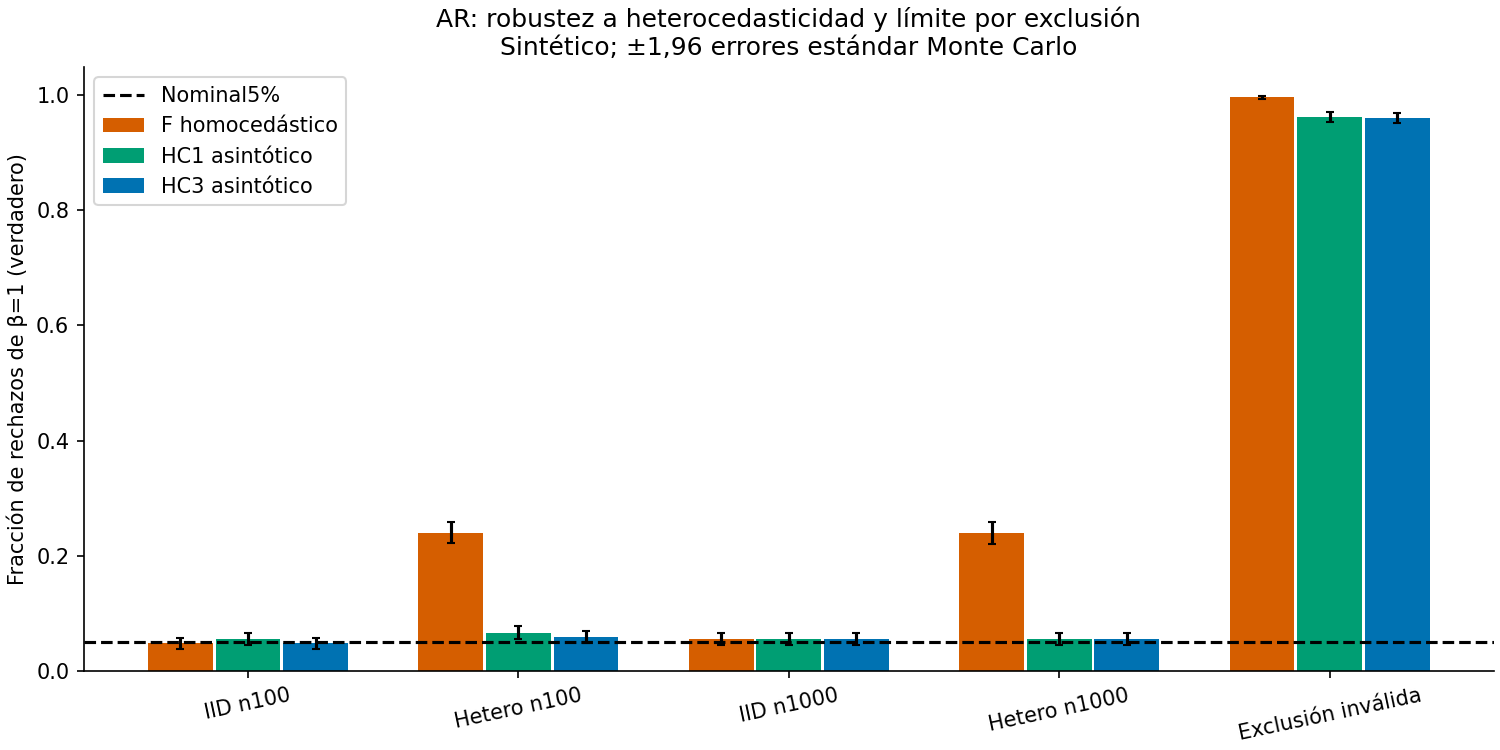

In [3]:
display(Image(filename=str(root/"results/comparison.png")))

## Checks y sensibilidad
Validar invariancia de AR al cambiar relevancia manteniendo misma nula y shocks, y evaluar umbrales registrados sin forzar resultado.

In [4]:
a=sample(23,500,True,c=0)
b=sample(23,500,True,c=10)
assert abs(robust_ar(*a,1)-robust_ar(*b,1))<1e-12
s=r["summary"][3]
print("HC3 dentro umbral:", .03<=s["rates"][2]<=.07)
print("Exceso F >=5pp:",s["rates"][0]-s["rates"][2]>=.05)
print((root/"results/costs.csv").read_text())

HC3 dentro umbral: True
Exceso F >=5pp: True
n,method,calls,seconds,python_peak_bytes
100,F,100,0.02230976699996745,23166
100,HC1,100,0.024343474999966475,21696
100,HC3,100,0.025460664999968685,21070
1000,F,100,0.02282894799998303,50721
1000,HC1,100,0.027022262000002684,78057
1000,HC3,100,0.024400130999993053,77961
10000,F,100,0.026024491999976362,406317
10000,HC1,100,0.030816225000023678,726263
10000,HC3,100,0.03288308200001211,726010



## Lectura crítica y límites
La inferencia robusta a relevancia débil y heterocedasticidad requiere instrumentos válidos. No prueba exclusión. HC3 puede ser conservador o distorsionado en muestras pequeñas; no se obtiene garantía uniforme de este Monte Carlo. No intervalos invertidos, clustering, HAC, instrumentos múltiples, poder ni datos reales. S2 local; garantía asintótica frente a F exacto solo en su DGP válido.

Siguiente: errores dependientes; inversión que preserve conjuntos no acotados; potencia bajo alternativas. Ver siete referencias en referencias.bib y análisis de 14 puntos en informe.md.

Notebook ejecutado secuencialmente con IPython limpio en proceso sin kernel/socket; errores abortan y outputs quedan persistidos.